# Fused early-fusion MLP + ablation (price / technical / fundamentals / news)


## 0. Imports & config

In [25]:
import os, numpy as np, pandas as pd
import tensorflow as tf
from tensorflow.keras import Sequential, layers, callbacks
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error as MAE, mean_squared_error as MSE, r2_score

tf.get_logger().setLevel("ERROR")

PRICE_PATH = "/kaggle/input/datasets/raheenz/ubl-news-price/UBL.csv"
FUND_PATH  = "/kaggle/input/datasets/raheenz/ubl-news-price/UBL_fundamental_features.csv"
NEWS_PATH  = "/kaggle/input/datasets/raheenz/ubl-news-price/ubl_news_clean.csv"
FEAT_DIR   = "/kaggle/working"

START, END    = "2021-09-30", "2026-06-30"
W             = 30   
TRAIN_END, VAL_END = "2025-01-23", "2025-10-10" #  chronological split (on the date being predicted)
HALF_LIFE, N_PCA, RERUN_FINBERT = 3, 8, False
SEEDS = [42, 43, 44]
os.makedirs(FEAT_DIR, exist_ok=True)

In [26]:
from __future__ import annotations
from dataclasses import dataclass
from typing import Dict, List, Tuple


@dataclass(frozen=True)
class CorrelatedGroup:
    name: str
    features: Tuple[str, ...]
    signs: Tuple[int, ...]


class FundamentalFeatureAnalyzer:
    """Fit on training data only. transform() keeps the original features and
    appends one standardized composite signal per correlated group (>= 2 features)."""

    def __init__(self, correlation_threshold: float = 0.8) -> None:
        if not 0 < correlation_threshold <= 1:
            raise ValueError("correlation_threshold must be between 0 and 1")
        self.correlation_threshold = correlation_threshold
        self.feature_means_ = None
        self.feature_stds_ = None
        self.correlation_ = None
        self.groups_: List[CorrelatedGroup] = []

    def fit(self, features: pd.DataFrame) -> "FundamentalFeatureAnalyzer":
        nf = self._validate_features(features)
        self.feature_means_ = nf.mean()
        self.feature_stds_ = nf.std(ddof=0).replace(0, 1.0)
        self.correlation_ = nf.corr()
        self.groups_ = []
        for component in self._find_correlated_components(self.correlation_):
            if len(component) < 2:
                continue
            anchor = component[0]
            signs = tuple(1 if self.correlation_.loc[anchor, f] >= 0 else -1 for f in component)
            self.groups_.append(CorrelatedGroup(
                name=f"fundamental_signal_{len(self.groups_) + 1}",
                features=tuple(component), signs=signs))
        return self

    def transform(self, features: pd.DataFrame) -> pd.DataFrame:
        if self.feature_means_ is None:
            raise RuntimeError("Call fit before transform")
        nf = self._validate_features(features)
        missing = set(self.feature_means_.index) - set(nf.columns)
        if missing:
            raise ValueError("Missing features: " + ", ".join(sorted(missing)))
        out = nf.copy()
        std = (nf[self.feature_means_.index] - self.feature_means_) / self.feature_stds_
        for g in self.groups_:
            out[g.name] = sum(std[f] * s for f, s in zip(g.features, g.signs)) / len(g.features)
        return out

    def fit_transform(self, features):
        return self.fit(features).transform(features)

    def correlated_pairs(self) -> pd.DataFrame:
        if self.correlation_ is None:
            raise RuntimeError("Call fit before correlated_pairs")
        pairs, cols = [], list(self.correlation_.columns)
        for i, a in enumerate(cols):
            for b in cols[i + 1:]:
                c = self.correlation_.loc[a, b]
                if abs(c) >= self.correlation_threshold:
                    pairs.append({"feature_a": a, "feature_b": b, "correlation": c})
        return pd.DataFrame(pairs, columns=["feature_a", "feature_b", "correlation"]).sort_values(
            "correlation", key=lambda v: v.abs(), ascending=False, ignore_index=True)

    def _validate_features(self, features):
        if not isinstance(features, pd.DataFrame):
            raise TypeError("features must be a pandas DataFrame")
        if features.empty:
            raise ValueError("features must not be empty")
        nf = features.select_dtypes(include=[np.number])
        if nf.shape[1] != features.shape[1]:
            raise TypeError("features must contain numeric columns only")
        if nf.isna().any().any():
            raise ValueError("features must not contain missing values")
        return nf

    def _find_correlated_components(self, corr):
        adj = {c: set() for c in corr.columns}
        for i, a in enumerate(corr.columns):
            for b in corr.columns[i + 1:]:
                if abs(corr.loc[a, b]) >= self.correlation_threshold:
                    adj[a].add(b); adj[b].add(a)
        comps, unseen = [], set(adj)
        while unseen:
            start = next(iter(unseen)); stack, comp = [start], []
            unseen.remove(start)
            while stack:
                cur = stack.pop(); comp.append(cur)
                for n in adj[cur]:
                    if n in unseen:
                        unseen.remove(n); stack.append(n)
            comps.append([c for c in corr.columns if c in comp])
        return comps

In [27]:
class FundamentalFactorEngineer:
    """Create finance factors supported by the available UBL columns."""

    def __init__(self):
        self.growth_means_ = None
        self.growth_stds_ = None
        self.quality_means_ = None
        self.quality_stds_ = None

    def fit(self, features):
        factors = self._calculate_raw_factors(features)
        growth_columns = [
            c for c in ["Revenue Growth (YoY)", "Net Income Growth", "EPS Growth"]
            if c in factors
        ]
        quality_columns = [
            c for c in [
                "fundamental_earnings_margin",
                "fundamental_earnings_to_assets",
                "fundamental_cash_to_assets",
            ] if c in factors
        ]
        if growth_columns:
            self.growth_means_ = factors[growth_columns].mean()
            self.growth_stds_ = factors[growth_columns].std(ddof=0).replace(0, 1.0)
        if quality_columns:
            self.quality_means_ = factors[quality_columns].mean()
            self.quality_stds_ = factors[quality_columns].std(ddof=0).replace(0, 1.0)
        return self

    def transform(self, features):
        if self.growth_means_ is None and self.quality_means_ is None:
            raise RuntimeError("Call fit before transform")

        factors = self._calculate_raw_factors(features)
        result = features.copy()
        if self.growth_means_ is not None:
            columns = [c for c in self.growth_means_.index if c in factors]
            result["fundamental_growth_score"] = (
                (factors[columns] - self.growth_means_[columns])
                / self.growth_stds_[columns]
            ).mean(axis=1)
        if self.quality_means_ is not None:
            columns = [c for c in self.quality_means_.index if c in factors]
            result["fundamental_quality_score"] = (
                (factors[columns] - self.quality_means_[columns])
                / self.quality_stds_[columns]
            ).mean(axis=1)
        for column in factors.columns:
            if column not in result.columns:
                result[column] = factors[column]
        if {"fundamental_growth_score", "fundamental_quality_score"}.issubset(result.columns):
            result["fundamental_growth_quality"] = (
                result["fundamental_growth_score"]
                * result["fundamental_quality_score"]
            )
        result = result.replace([np.inf, -np.inf], np.nan)
        if result.isna().any().any():
            raise ValueError("Fundamental factors contain missing or non-finite values")
        return result

    def fit_transform(self, features):
        return self.fit(features).transform(features)

    @staticmethod
    def _calculate_raw_factors(features):
        required = {"Revenue", "Net Income", "Total Assets", "Cash & Equivalents"}
        missing = required - set(features.columns)
        if missing:
            raise ValueError("Missing fundamental columns: " + ", ".join(sorted(missing)))
        revenue = features["Revenue"].replace(0, np.nan)
        assets = features["Total Assets"].replace(0, np.nan)
        factors = pd.DataFrame({
            "fundamental_earnings_margin": features["Net Income"] / revenue,
            "fundamental_earnings_to_assets": features["Net Income"] / assets,
            "fundamental_asset_efficiency": revenue / assets,
            "fundamental_cash_to_assets": features["Cash & Equivalents"] / assets,
        }, index=features.index)
        growth = [c for c in ["Revenue Growth (YoY)", "Net Income Growth", "EPS Growth"] if c in features]
        return pd.concat([features[growth], factors], axis=1)


## 1. Price: load & clean 

In [28]:
df = pd.read_csv(PRICE_PATH)
df.columns = df.columns.str.strip().str.upper()
df["DATE"] = pd.to_datetime(df["DATE"])
df = df[df["DATE"] >= "2021-01-01"].drop_duplicates()
ok = ((df[["OPEN","HIGH","LOW","CLOSE"]] > 0).all(axis=1) & (df["VOLUME"] >= 0)
      & (df["HIGH"] >= df[["OPEN","CLOSE","LOW"]].max(axis=1))
      & (df["LOW"] <= df[["OPEN","CLOSE","HIGH"]].min(axis=1)))
df = df[ok].sort_values("DATE")
df = df[(df.DATE >= START) & (df.DATE <= END)].reset_index(drop=True)
df["DATE"] = df["DATE"].astype("datetime64[ns]")
assert df.DATE.is_unique
print(len(df), df.DATE.min(), df.DATE.max())

1176 2021-09-30 00:00:00 2026-06-30 00:00:00


## 2. Price features & target

In [29]:
df["ret"] = np.log(df.CLOSE).diff()
df["hl_range"] = (df.HIGH - df.LOW) / df.CLOSE
df["oc_change"] = (df.CLOSE - df.OPEN) / df.OPEN
df["log_vol"] = np.log1p(df.VOLUME)
df["ma5_ratio"] = df.CLOSE / df.CLOSE.rolling(5).mean() - 1
df["ma20_ratio"] = df.CLOSE / df.CLOSE.rolling(20).mean() - 1
df["vol10"] = df.ret.rolling(10).std()
df["target_ret"] = df.ret.shift(-1)          # next-day log return
df["tdate"] = df.DATE.shift(-1)              # date being predicted
df["next_close"] = df.CLOSE.shift(-1)

PRICE_F = ["ret","hl_range","oc_change","log_vol","ma5_ratio","ma20_ratio","vol10"]

## 3. Technical indicators 

In [30]:
!pip install -q TA-Lib

In [31]:
import talib

close, high, low = df["CLOSE"].values.astype(float), df["HIGH"].values.astype(float), df["LOW"].values.astype(float)

df["EMA_12"] = talib.EMA(close, timeperiod=12)
df["EMA_26"] = talib.EMA(close, timeperiod=26)
df["MACD"], _, _ = talib.MACD(close, fastperiod=12, slowperiod=26, signalperiod=9)
df["SAR"] = talib.SAR(high, low, acceleration=0.02, maximum=0.2)
df["BB_UPPER"], df["BB_MIDDLE"], df["BB_LOWER"] = talib.BBANDS(
    close, timeperiod=20, nbdevup=2, nbdevdn=2, matype=0)
df["SLOWK"], df["SLOWD"] = talib.STOCH(
    high, low, close, fastk_period=5, slowk_period=3, slowk_matype=0,
    slowd_period=3, slowd_matype=0)

TECH = ["OPEN","HIGH","LOW","CLOSE","VOLUME",
        "EMA_12","EMA_26","MACD","SAR",
        "BB_UPPER","BB_MIDDLE","BB_LOWER","SLOWK","SLOWD"]

## 4. Fundamentals: load, impute, merge backward on filing date


In [32]:
fund = pd.read_csv(FUND_PATH, na_values=["-", "--", ""])
fund = fund.rename(columns={"Unnamed: 0": "QUARTER", "Unnamed: 1": "DATE"})
fund["DATE"] = pd.to_datetime(fund["DATE"].str.extract(r"([A-Z][a-z]{2} \d{2}, \d{4})")[0])
fund = fund.sort_values("DATE").reset_index(drop=True)

# STEP 1: derivable YoY growth fields
fund["Revenue Growth (YoY)"] = fund["Revenue Growth (YoY)"].fillna(fund["Revenue"].pct_change(4) * 100)
fund["Net Income Growth"]    = fund["Net Income Growth"].fillna(fund["Net Income"].pct_change(4) * 100)
fund["EPS Growth"]           = fund["EPS Growth"].fillna(fund["EPS (Basic)"].pct_change(4) * 100)

# STEP 2: fill missing raw values with mean of previous 4 quarters
for col in ["Revenue", "Net Income", "EPS (Basic)", "EPS (Diluted)"]:
    rolling_mean = fund[col].shift(1).rolling(window=4, min_periods=2).mean()
    fund[col] = fund[col].fillna(rolling_mean)

# STEP 3: recalc derived growth fields
fund["Revenue Growth (YoY)"] = fund["Revenue Growth (YoY)"].fillna(fund["Revenue"].pct_change(4) * 100)
fund["Net Income Growth"]    = fund["Net Income Growth"].fillna(fund["Net Income"].pct_change(4) * 100)
fund["EPS Growth"]           = fund["EPS Growth"].fillna(fund["EPS (Basic)"].pct_change(4) * 100)

# ---- leak-safe merge: latest filing on/before each trading day ----
fund["DATE"] = fund["DATE"].astype("datetime64[ns]")
fund["FUND_ASOF"] = fund["DATE"]
merged = pd.merge_asof(df[["DATE"]], fund, on="DATE", direction="backward")

for col in ["Revenue Growth (YoY)", "Net Income Growth", "EPS Growth"]:
    merged[col] = pd.to_numeric(merged[col].astype(str).str.replace("%", "", regex=False), errors="coerce")

FUND = ["Revenue", "Revenue Growth (YoY)", "Net Income", "Net Income Growth",
        "EPS (Basic)", "EPS (Diluted)", "EPS Growth", "Total Assets", "Cash & Equivalents"]
for c in FUND: df[c] = merged[c].astype(float).values
df["fund_asof"] = merged["FUND_ASOF"].values
assert (df["fund_asof"].dropna() <= df.loc[df["fund_asof"].notna(), "DATE"]).all()   # no look-ahead
print("days before first filing (no fundamentals yet):", int(df["fund_asof"].isna().sum()))

days before first filing (no fundamentals yet): 0


/tmp/ipykernel_50/3899897271.py:7: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  fund["Revenue Growth (YoY)"] = fund["Revenue Growth (YoY)"].fillna(fund["Revenue"].pct_change(4) * 100)
/tmp/ipykernel_50/3899897271.py:8: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  fund["Net Income Growth"]    = fund["Net Income Growth"].fillna(fund["Net Income"].pct_change(4) * 100)
/tmp/ipykernel_50/3899897271.py:9: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or spec

## 5. News: FinBERT cache → daily features aligned on `feature_date` 

In [33]:
CACHE_S, CACHE_E = f"{FEAT_DIR}/article_scored.csv", f"{FEAT_DIR}/article_emb.npy"

if os.path.exists(CACHE_S) and os.path.exists(CACHE_E) and not RERUN_FINBERT:
    arts = pd.read_csv(CACHE_S, parse_dates=["pub_date", "feature_date"]); E = np.load(CACHE_E)
    print(f"loaded cached FinBERT output: {len(arts)} articles")
else:
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("device:", device)

    arts = pd.read_csv(NEWS_PATH, parse_dates=["pub_date", "feature_date"])
    tok = AutoTokenizer.from_pretrained("ProsusAI/finbert")
    model = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert").to(device).eval()
    id2 = {int(k): v.lower() for k, v in model.config.id2label.items()}
    POS, NEG, NEU = [[k for k, v in id2.items() if v == name][0] for name in ("positive", "negative", "neutral")]

    # split long articles into 510-token chunks
    chunks = []
    for i, (t, x) in enumerate(zip(arts["title"], arts["text"])):
        ids = tok(f"{t}. {x}", add_special_tokens=False)["input_ids"]
        for s in range(0, max(len(ids), 1), 510):
            chunks.append((i, ids[s:s + 510]))
    print(f"{len(arts)} articles -> {len(chunks)} chunks")

    BATCH, probs, embs = 8, [], []
    with torch.no_grad():
        for b in range(0, len(chunks), BATCH):
            batch = [[tok.cls_token_id] + ids + [tok.sep_token_id] for _, ids in chunks[b:b + BATCH]]
            L = max(len(x) for x in batch)
            input_ids = torch.tensor([x + [tok.pad_token_id] * (L - len(x)) for x in batch]).to(device)
            out = model(input_ids=input_ids, attention_mask=(input_ids != tok.pad_token_id).long(), output_hidden_states=True)
            probs.append(torch.softmax(out.logits, -1).cpu().numpy())
            embs.append(out.hidden_states[-1][:, 0, :].cpu().numpy())
            if (b // BATCH) % 10 == 0: print(f"  {min(b + BATCH, len(chunks))}/{len(chunks)} chunks")
    probs, embs = np.vstack(probs), np.vstack(embs)

    # chunks -> articles
    rows = np.array([r for r, _ in chunks]); w = np.array([len(ids) for _, ids in chunks], float)
    P, E, Wt = np.zeros((len(arts), 3)), np.zeros((len(arts), 768)), np.zeros(len(arts))
    np.add.at(P, rows, probs * w[:, None]); np.add.at(E, rows, embs * w[:, None]); np.add.at(Wt, rows, w)
    P /= Wt[:, None]; E /= Wt[:, None]
    arts["p_pos"], arts["p_neg"], arts["p_neu"] = P[:, POS], P[:, NEG], P[:, NEU]
    arts["sentiment"] = arts["p_pos"] - arts["p_neg"]
    arts.to_csv(CACHE_S, index=False); np.save(CACHE_E, E)
    print("saved FinBERT output to", FEAT_DIR)

loaded cached FinBERT output: 277 articles


In [34]:
# each article -> the first trading day on/after its feature_date
arts["feature_date"] = arts["feature_date"].astype("datetime64[ns]")
arts["row"] = np.arange(len(arts))
a = pd.merge_asof(arts.sort_values("feature_date"), df[["DATE"]].rename(columns={"DATE": "trade_date"}),
                  left_on="feature_date", right_on="trade_date", direction="forward").dropna(subset=["trade_date"]).reset_index(drop=True)
assert (a["trade_date"] >= a["feature_date"]).all()                                   # no look-ahead
E_s = E[a["row"].values]

g = a.groupby("trade_date")
daily = pd.DataFrame({"n_articles": g.size(), "sent_mean": g["sentiment"].mean(),
                      "sent_extreme": g["sentiment"].agg(lambda s: s.loc[s.abs().idxmax()])})
df = df.join(daily, on="DATE")
df["has_news"] = df["n_articles"].notna().astype(int)
df[["n_articles", "sent_mean", "sent_extreme"]] = df[["n_articles", "sent_mean", "sent_extreme"]].fillna(0)

D = np.zeros((len(df), 768)); pos = {d: i for i, d in enumerate(df["DATE"])}
for d, idx_ in g.indices.items(): D[pos[d]] = E_s[idx_].mean(axis=0)

# news recency / memory features (causal loop)
ds, last, m, memo, decay = [], -1, 0.0, [], 0.5 ** (1 / HALF_LIFE)
for i, (h, s) in enumerate(zip(df["has_news"], df["sent_mean"])):
    if h: last = i
    ds.append(i - last if last >= 0 else 60); m = m * decay + s; memo.append(m)
df["recency"] = 0.5 ** (np.minimum(ds, 60) / HALF_LIFE)
df["sent_decay"] = memo

NEWS = ["n_articles", "sent_mean", "sent_extreme", "has_news", "recency", "sent_decay"]
print(f"days with news: {int(df.has_news.sum())} ({df.has_news.mean():.1%})")

days with news: 167 (14.2%)


## 6. Unified sample table + chronological split
One row per sample `t`: price window `[t-29..t]`, tech/fund/news at `t`, target = return `t→t+1`. A sample exists only if **all four blocks** are available, so every ablation variant is trained and scored on the identical rows. Split is on the date being predicted (`tdate`); no shuffling.

In [35]:
# Fundamental factors available before the unified-sample split.
# These are row-wise ratios; no train/test statistics are used here.
FUND_DERIVED = [
    "fundamental_earnings_margin",
    "fundamental_earnings_to_assets",
    "fundamental_asset_efficiency",
    "fundamental_cash_to_assets",
]

revenue = df["Revenue"].replace(0, np.nan)
assets = df["Total Assets"].replace(0, np.nan)
df["fundamental_earnings_margin"] = df["Net Income"] / revenue
df["fundamental_earnings_to_assets"] = df["Net Income"] / assets
df["fundamental_asset_efficiency"] = revenue / assets
df["fundamental_cash_to_assets"] = df["Cash & Equivalents"] / assets

df[FUND_DERIVED] = df[FUND_DERIVED].replace([np.inf, -np.inf], np.nan)
print("Added unified-table fundamental columns:", FUND_DERIVED)
display(df[["DATE"] + FUND_DERIVED].head())

Added unified-table fundamental columns: ['fundamental_earnings_margin', 'fundamental_earnings_to_assets', 'fundamental_asset_efficiency', 'fundamental_cash_to_assets']


,DATE,fundamental_earnings_margin,fundamental_earnings_to_assets,fundamental_asset_efficiency,fundamental_cash_to_assets
0,2021-09-30,0.260678,0.002521,0.009669,0.099466
1,2021-10-01,0.260678,0.002521,0.009669,0.099466
2,2021-10-04,0.260678,0.002521,0.009669,0.099466
3,2021-10-05,0.260678,0.002521,0.009669,0.099466
4,2021-10-06,0.260678,0.002521,0.009669,0.099466


In [36]:
price_ok = df[PRICE_F].notna().all(axis=1)
win_ok   = price_ok.astype(int).rolling(W).sum().eq(W)
tech_ok  = df[TECH].notna().all(axis=1)
fund_ok  = df[FUND + FUND_DERIVED].notna().all(axis=1)
tgt_ok   = df[["target_ret", "tdate", "next_close"]].notna().all(axis=1)
print(f"raw days {len(df)} | price-window ok {win_ok.sum()} | tech ok {tech_ok.sum()} | fund + derived ok {fund_ok.sum()} | target ok {tgt_ok.sum()}")

idx = np.where((win_ok & tech_ok & fund_ok & tgt_ok).values)[0]
print("unified samples:", len(idx), "| interior gaps:", int((np.diff(idx) > 1).sum()))

Xp = np.stack([df[PRICE_F].values[i-W+1:i+1] for i in idx])        # (N, W, 7)
Xt = df[TECH].values[idx]
Xf = df[FUND].values[idx]
Xn_raw = df[NEWS].values[idx]
Dm  = D[idx]; has = df["has_news"].values[idx]
y   = df["target_ret"].values[idx]
td  = pd.DatetimeIndex(df["tdate"].values[idx])
pc  = df["CLOSE"].values[idx]                 # today's close
nc  = df["next_close"].values[idx]            # actual next close

tr = np.asarray(td <= pd.Timestamp(TRAIN_END))
va = np.asarray((td > pd.Timestamp(TRAIN_END)) & (td <= pd.Timestamp(VAL_END)))
te = np.asarray(td > pd.Timestamp(VAL_END))
print("train / val / test:", tr.sum(), va.sum(), te.sum())
assert td[tr].max() < td[va].min() and td[va].max() < td[te].min()   # chronological, no overlap

raw days 1176 | price-window ok 1128 | tech ok 1143 | fund + derived ok 1176 | target ok 1175
unified samples: 1127 | interior gaps: 0
train / val / test: 774 176 177


In [37]:
# ===== 6.1 Export feature files + fused dataset + dictionary =====
BASE   = ["DATE", "OPEN", "HIGH", "LOW", "CLOSE", "VOLUME"]
TECH_X = [c for c in TECH if c not in BASE]          # indicators only (OHLCV lives in price)
TARGET = ["target_ret", "tdate", "next_close"]

# 1) technical indicators (DATE-keyed)
df[["DATE"] + TECH_X].to_csv(f"{FEAT_DIR}/technical_indicators.csv", index=False)

# 2) news features (DATE-keyed) + daily FinBERT embeddings (row i = df row i)
df[["DATE"] + NEWS].to_csv(f"{FEAT_DIR}/news_features.csv", index=False)
np.save(f"{FEAT_DIR}/news_daily_finbert768.npy", D)

# 3) fundamentals after imputation (quarterly, one row per filing)
fund.to_csv(f"{FEAT_DIR}/fundamentals_imputed.csv", index=False)

# 4) fused dataset: price + price features + technical + fundamentals + news + target
fused = df[BASE + PRICE_F + TECH_X + FUND + FUND_DERIVED + ["fund_asof"] + NEWS + TARGET].copy()
fused["in_unified"] = 0;          fused.loc[idx, "in_unified"] = 1
fused["split"] = "excluded"
fused.loc[idx[tr], "split"] = "train"
fused.loc[idx[va], "split"] = "val"
fused.loc[idx[te], "split"] = "test"
fused.to_csv(f"{FEAT_DIR}/ubl_fused_dataset.csv", index=False)

# 5) data dictionary
desc = {
 "DATE": ("price", "Trading day t (feature date)"),
 "OPEN": ("price", "Opening price"), "HIGH": ("price", "Daily high"), "LOW": ("price", "Daily low"),
 "CLOSE": ("price", "Closing price"), "VOLUME": ("price", "Shares traded"),
 "ret": ("price", "Log return ln(CLOSE_t / CLOSE_t-1)"),
 "hl_range": ("price", "(HIGH - LOW) / CLOSE"),
 "oc_change": ("price", "(CLOSE - OPEN) / OPEN"),
 "log_vol": ("price", "log(1 + VOLUME)"),
 "ma5_ratio": ("price", "CLOSE / 5-day MA - 1"),
 "ma20_ratio": ("price", "CLOSE / 20-day MA - 1"),
 "vol10": ("price", "10-day rolling std of ret"),
 "EMA_12": ("technical", "12-day EMA"), "EMA_26": ("technical", "26-day EMA"),
 "MACD": ("technical", "MACD line (12/26/9)"), "SAR": ("technical", "Parabolic SAR (0.02/0.2)"),
 "BB_UPPER": ("technical", "Bollinger upper (20, 2 std)"), "BB_MIDDLE": ("technical", "Bollinger middle (20-day SMA)"),
 "BB_LOWER": ("technical", "Bollinger lower (20, 2 std)"),
 "SLOWK": ("technical", "Stochastic %K (5,3,3)"), "SLOWD": ("technical", "Stochastic %D (5,3,3)"),
 "Revenue": ("fundamental", "Quarterly revenue (gaps imputed: mean of prev 4 quarters)"),
 "Revenue Growth (YoY)": ("fundamental", "YoY revenue growth %"),
 "Net Income": ("fundamental", "Quarterly net income (imputed as above)"),
 "Net Income Growth": ("fundamental", "YoY net income growth %"),
 "EPS (Basic)": ("fundamental", "Basic EPS (imputed as above)"),
 "EPS (Diluted)": ("fundamental", "Diluted EPS (imputed as above)"),
 "EPS Growth": ("fundamental", "YoY EPS growth %"),
 "Total Assets": ("fundamental", "Total assets"), "Cash & Equivalents": ("fundamental", "Cash & equivalents"),
 "fundamental_earnings_margin": ("fundamental", "Net income / revenue"),
 "fundamental_earnings_to_assets": ("fundamental", "Net income / total assets"),
 "fundamental_asset_efficiency": ("fundamental", "Revenue / total assets"),
 "fundamental_cash_to_assets": ("fundamental", "Cash & equivalents / total assets"),
 "fund_asof": ("fundamental", "Filing date of latest report known on day t (backward merge, no look-ahead)"),
 "n_articles": ("news", "Articles mapped to this trading day"),
 "sent_mean": ("news", "Mean FinBERT sentiment (p_pos - p_neg) that day"),
 "sent_extreme": ("news", "Sentiment of the article with the largest |sentiment|"),
 "has_news": ("news", "1 if at least one article that day"),
 "recency": ("news", f"0.5^(days since last news / {HALF_LIFE}), capped at 60 days"),
 "sent_decay": ("news", f"Exponentially decayed running sentiment (half-life {HALF_LIFE} days)"),
 "target_ret": ("target", "Next-day log return (t -> t+1)"),
 "tdate": ("target", "Date being predicted (t+1); splits are done on this"),
 "next_close": ("target", "Actual next-day close"),
 "in_unified": ("meta", "1 if row has all blocks + full 30-day window + target"),
 "split": ("meta", f"train (<= {TRAIN_END}) / val (<= {VAL_END}) / test / excluded"),
}
dd = pd.DataFrame([(c, *desc[c]) for c in fused.columns], columns=["column", "block", "description"])
dd["non_null"] = [int(fused[c].notna().sum()) for c in dd["column"]]
dd.to_csv(f"{FEAT_DIR}/ubl_fused_dataset_DICTIONARY.csv", index=False)

print("fused:", fused.shape, "| unified rows:", int(fused.in_unified.sum()), "|", fused.split.value_counts().to_dict())
dd

fused: (1176, 47) | unified rows: 1127 | {'train': 774, 'test': 177, 'val': 176, 'excluded': 49}


,column,block,description,non_null
0,DATE,price,Trading day t (feature date),1176
1,OPEN,price,Opening price,1176
2,HIGH,price,Daily high,1176
3,LOW,price,Daily low,1176
4,CLOSE,price,Closing price,1176
5,VOLUME,price,Shares traded,1176
6,ret,price,Log return ln(CLOSE_t / CLOSE_t-1),1175
7,hl_range,price,(HIGH - LOW) / CLOSE,1176
8,oc_change,price,(CLOSE - OPEN) / OPEN,1176
9,log_vol,price,log(1 + VOLUME),1176


## 7. Per-block scalers (fit on train only) → feature blocks

In [38]:
blocks = {}

# price: StandardScaler on windowed features, flattened  
sx = StandardScaler().fit(Xp[tr].reshape(-1, len(PRICE_F)))
blocks["price"] = sx.transform(Xp.reshape(-1, len(PRICE_F))).reshape(len(Xp), -1)

# technical: StandardScaler
blocks["tech"] = StandardScaler().fit(Xt[tr]).transform(Xt)

# fundamentals: StandardScaler 
blocks["fund"] = StandardScaler().fit(Xf[tr]).transform(Xf)

# news: PCA on FinBERT embeddings (fit on train news-days only, zero on no-news days) + StandardScaler  
pca = PCA(N_PCA, random_state=0).fit(Dm[tr][has[tr] == 1])
EMB = pca.transform(Dm) * has[:, None]
Xn = np.hstack([Xn_raw, EMB])
blocks["news"] = StandardScaler().fit(Xn[tr]).transform(Xn)

print({k: v.shape for k, v in blocks.items()})

{'price': (1127, 210), 'tech': (1127, 14), 'fund': (1127, 9), 'news': (1127, 14)}


unique filings in train: 14
{'price': (1127, 210), 'tech': (1127, 14), 'fund': (1127, 9), 'news': (1127, 14), 'fund_sig': (1127, 11), 'fund_comp': (1127, 4)}

Correlated pairs:


,feature_a,feature_b,correlation
0,EPS (Basic),EPS (Diluted),1.000000
1,Net Income Growth,EPS Growth,1.000000
2,Net Income,EPS (Basic),0.999999
3,Net Income,EPS (Diluted),0.999999
4,Revenue,Net Income,0.909361
5,Revenue,EPS (Basic),0.909130
6,Revenue,EPS (Diluted),0.909130
7,Revenue,Total Assets,0.881055


fundamental_signal_1 = +[Revenue] +[Net Income] +[EPS (Basic)] +[EPS (Diluted)] +[Total Assets]
fundamental_signal_2 = +[Net Income Growth] +[EPS Growth]


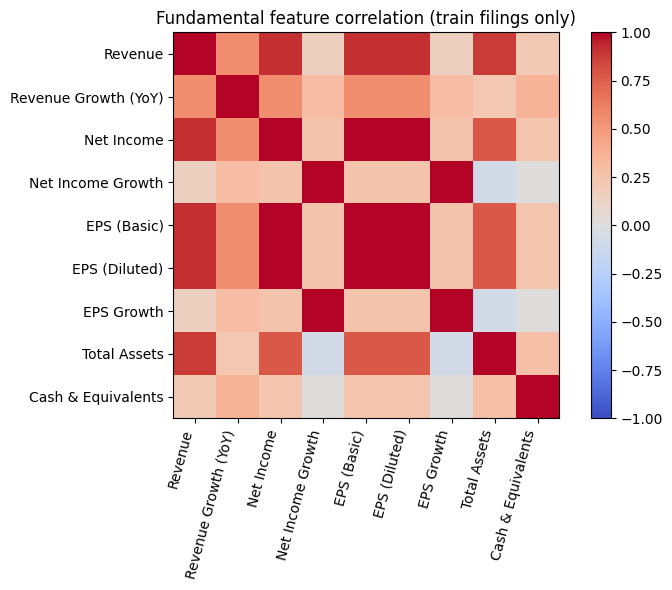

In [39]:
import matplotlib.pyplot as plt

CORR_THR = 0.8
asof = df["fund_asof"].values[idx]          # filing date behind each sample's fundamentals

def fit_fund_blocks(Xf_fit, asof_fit, thr=CORR_THR):
    """Fit analyzer + scalers on fit rows only. Analyzer sees one row per filing
    (fundamentals are quarterly, forward-filled to daily)."""
    fit_df = pd.DataFrame(Xf_fit, columns=FUND)
    uniq = ~pd.Series(asof_fit).duplicated().values
    an = FundamentalFeatureAnalyzer(thr).fit(fit_df[uniq])
    sig_cols  = [g.name for g in an.groups_]
    grouped   = {f for g in an.groups_ for f in g.features}
    aug_cols  = FUND + sig_cols                                          # originals + composites
    comp_cols = sig_cols + [f for f in FUND if f not in grouped]         # composites replace correlated originals
    aug = lambda X: an.transform(pd.DataFrame(X, columns=FUND))
    A = aug(Xf_fit)
    sc_aug, sc_comp = StandardScaler().fit(A[aug_cols]), StandardScaler().fit(A[comp_cols])
    return {"fund_sig":  lambda X: sc_aug.transform(aug(X)[aug_cols]),
            "fund_comp": lambda X: sc_comp.transform(aug(X)[comp_cols])}, an

fund_fns, fund_an = fit_fund_blocks(Xf[tr], asof[tr])
for k, fn in fund_fns.items():
    blocks[k] = fn(Xf)

print("unique filings in train:", pd.Series(asof[tr]).nunique())
print({k: v.shape for k, v in blocks.items()})
print("\nCorrelated pairs:"); display(fund_an.correlated_pairs())
for g in fund_an.groups_:
    print(g.name, "=", " ".join(f"{'+' if s > 0 else '-'}[{f}]" for f, s in zip(g.features, g.signs)))
if not fund_an.groups_:
    print("No groups at this threshold -> fund_sig == fund. Try CORR_THR = 0.7.")

cm = fund_an.correlation_
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(cm.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=75, ha="right")
ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.columns)
plt.colorbar(im); ax.set_title("Fundamental feature correlation (train filings only)")
plt.tight_layout(); plt.show()

In [40]:
# Finance factors supported by the available fundamental columns. Fit on train only.
fund_factor_engineer = FundamentalFactorEngineer().fit(
    pd.DataFrame(Xf[tr], columns=FUND)
)
fund_factors = fund_factor_engineer.transform(
    pd.DataFrame(Xf, columns=FUND)
)
added_factor_cols = [c for c in fund_factors.columns if c not in FUND]

# Combine raw fundamentals, correlation signals, and finance factors.
train_fund = pd.DataFrame(Xf[tr], columns=FUND)
train_fund = train_fund.loc[~pd.Series(asof[tr]).duplicated().values]
repository_fund_analyzer = FundamentalFeatureAnalyzer(CORR_THR).fit(train_fund)
fund_with_signals = repository_fund_analyzer.transform(pd.DataFrame(Xf, columns=FUND))
signal_cols = [g.name for g in repository_fund_analyzer.groups_]
fund_combined = pd.concat(
    [
        fund_with_signals[FUND + signal_cols].reset_index(drop=True),
        fund_factors[added_factor_cols].reset_index(drop=True),
    ],
    axis=1,
)
combined_cols = list(fund_combined.columns)
combined_scaler = StandardScaler().fit(fund_combined.iloc[tr])
blocks["fund_raw_analyzed"] = combined_scaler.transform(fund_combined)

print("\nAdded finance-factor columns:")
print(added_factor_cols)
print("\nCombined fundamental input columns:")
print(combined_cols)
print("\nAdded finance-factor values:")
display(fund_factors[added_factor_cols].head())
print("\nCombined raw + analyzed values:")
display(fund_combined.head())
print("\nCorrelated pairs used:")
display(repository_fund_analyzer.correlated_pairs())
print("\nCombined fundamental block shape:", blocks["fund_raw_analyzed"].shape)



Added finance-factor columns:
['fundamental_growth_score', 'fundamental_quality_score', 'fundamental_earnings_margin', 'fundamental_earnings_to_assets', 'fundamental_asset_efficiency', 'fundamental_cash_to_assets', 'fundamental_growth_quality']

Combined fundamental input columns:
['Revenue', 'Revenue Growth (YoY)', 'Net Income', 'Net Income Growth', 'EPS (Basic)', 'EPS (Diluted)', 'EPS Growth', 'Total Assets', 'Cash & Equivalents', 'fundamental_signal_1', 'fundamental_signal_2', 'fundamental_growth_score', 'fundamental_quality_score', 'fundamental_earnings_margin', 'fundamental_earnings_to_assets', 'fundamental_asset_efficiency', 'fundamental_cash_to_assets', 'fundamental_growth_quality']

Added finance-factor values:


,fundamental_growth_score,fundamental_quality_score,fundamental_earnings_margin,fundamental_earnings_to_assets,fundamental_asset_efficiency,fundamental_cash_to_assets,fundamental_growth_quality
0,0.050945,0.641078,0.260678,0.002521,0.009669,0.099466,0.03266
1,0.050945,0.641078,0.260678,0.002521,0.009669,0.099466,0.03266
2,0.050945,0.641078,0.260678,0.002521,0.009669,0.099466,0.03266
3,0.050945,0.641078,0.260678,0.002521,0.009669,0.099466,0.03266
4,0.050945,0.641078,0.260678,0.002521,0.009669,0.099466,0.03266



Combined raw + analyzed values:


,Revenue,Revenue Growth (YoY),Net Income,Net Income Growth,EPS (Basic),EPS (Diluted),EPS Growth,Total Assets,Cash & Equivalents,fundamental_signal_1,fundamental_signal_2,fundamental_growth_score,fundamental_quality_score,fundamental_earnings_margin,fundamental_earnings_to_assets,fundamental_asset_efficiency,fundamental_cash_to_assets,fundamental_growth_quality
0,25917.0,38.78,6756.0,43.12,2.76,2.76,43.0,2680361.0,266604.0,-1.045827,-0.164175,0.050945,0.641078,0.260678,0.002521,0.009669,0.099466,0.03266
1,25917.0,38.78,6756.0,43.12,2.76,2.76,43.0,2680361.0,266604.0,-1.045827,-0.164175,0.050945,0.641078,0.260678,0.002521,0.009669,0.099466,0.03266
2,25917.0,38.78,6756.0,43.12,2.76,2.76,43.0,2680361.0,266604.0,-1.045827,-0.164175,0.050945,0.641078,0.260678,0.002521,0.009669,0.099466,0.03266
3,25917.0,38.78,6756.0,43.12,2.76,2.76,43.0,2680361.0,266604.0,-1.045827,-0.164175,0.050945,0.641078,0.260678,0.002521,0.009669,0.099466,0.03266
4,25917.0,38.78,6756.0,43.12,2.76,2.76,43.0,2680361.0,266604.0,-1.045827,-0.164175,0.050945,0.641078,0.260678,0.002521,0.009669,0.099466,0.03266



Correlated pairs used:


,feature_a,feature_b,correlation
0,EPS (Basic),EPS (Diluted),1.000000
1,Net Income Growth,EPS Growth,1.000000
2,Net Income,EPS (Basic),0.999999
3,Net Income,EPS (Diluted),0.999999
4,Revenue,Net Income,0.909361
5,Revenue,EPS (Basic),0.909130
6,Revenue,EPS (Diluted),0.909130
7,Revenue,Total Assets,0.881055



Combined fundamental block shape: (1127, 18)


## 8. Models & metrics  

In [69]:
def metrics(actual, pred, prev):
    return {
        "MAE": MAE(actual, pred),
        "RMSE": np.sqrt(MSE(actual, pred)),
        "MAPE": np.mean(np.abs((actual - pred) / actual)) * 100,
        "R²": r2_score(actual, pred),
        "Dir. acc.": np.mean(np.sign(actual - prev) == np.sign(pred - prev)) * 100,
    }

def build_mlp(n_in):
    m = Sequential([layers.Input((n_in,)), layers.Dense(64, activation="relu"), layers.Dropout(0.2),
                    layers.Dense(32, activation="relu"), layers.Dense(1)])
    m.compile("adam", "mse", metrics=["mae"]); return m

MLP_CFG = dict(build=build_mlp, epochs=200, patience=15, ysc=StandardScaler)

CFG = {
    "Price":              dict(blocks=["price"], **MLP_CFG),
    "Technical":          dict(blocks=["tech"],  **MLP_CFG),
    "Fundamentals":       dict(blocks=["fund"],  **MLP_CFG),
    "News":               dict(blocks=["news"],  **MLP_CFG),
    "Price+Tech":         dict(blocks=["price", "tech"], **MLP_CFG),
    "Price+Tech+Fund":    dict(blocks=["price", "tech", "fund"], **MLP_CFG),
    "All-4 fused":        dict(blocks=["price", "tech", "fund", "news"], **MLP_CFG),
    "All-4 minus Fund":   dict(blocks=["price", "tech", "news"], **MLP_CFG),
}

def run_one(name, seed):
    c = CFG[name]
    X = np.hstack([blocks[b] for b in c["blocks"]])
    ysc = c["ysc"]().fit(y[tr].reshape(-1, 1))
    ytr, yva = ysc.transform(y[tr].reshape(-1, 1)), ysc.transform(y[va].reshape(-1, 1))
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    mdl = c["build"](X.shape[1])
    mdl.fit(X[tr], ytr, validation_data=(X[va], yva), epochs=c["epochs"], batch_size=32, verbose=0,
            callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=c["patience"], restore_best_weights=True)])
    out = {}
    for sname, msk in (("Validation", va), ("Test", te)):
        r = ysc.inverse_transform(mdl.predict(X[msk], verbose=0)).ravel()
        out[sname] = metrics(nc[msk], pc[msk] * np.exp(r), pc[msk])
    return out

In [70]:
CFG.update({
    "Fund+Signals":              dict(blocks=["fund_sig"],                           **STD_CFG),
    "Fund composite":            dict(blocks=["fund_comp"],                          **STD_CFG),
    "Price+Tech+Fund+Signals":   dict(blocks=["price", "tech", "fund_sig"],          **STD_CFG),
    "Price+Tech+Fund composite": dict(blocks=["price", "tech", "fund_comp"],         **STD_CFG),
    "All-4 +Signals":            dict(blocks=["price", "tech", "fund_sig", "news"],  **STD_CFG),
    "All-4 composite":           dict(blocks=["price", "tech", "fund_comp", "news"], **STD_CFG),
})
CMP_SETS = {   # baseline first
    "Fundamentals only": ["Fundamentals", "Fund+Signals", "Fund composite"],
    "Price+Tech+Fund":   ["Price+Tech+Fund", "Price+Tech+Fund+Signals", "Price+Tech+Fund composite"],
    "All-4 fused":       ["All-4 fused", "All-4 +Signals", "All-4 composite"],
}

In [71]:
CFG.update({
    # Raw fundamentals + correlation signals + finance factors.
    "Fund raw + analyzed": dict(blocks=["fund_raw_analyzed"], **STD_CFG),
    "Price+Tech+Fund raw + analyzed": dict(
        blocks=["price", "tech", "fund_raw_analyzed"], **STD_CFG
    ),
    "All-4 raw + analyzed": dict(
        blocks=["price", "tech", "fund_raw_analyzed", "news"], **STD_CFG
    ),
})
CMP_SETS.update({
    "Fundamentals only": [
        "Fundamentals", "Fund+Signals", "Fund composite", "Fund raw + analyzed"
    ],
    "Price+Tech+Fund": [
        "Price+Tech+Fund", "Price+Tech+Fund+Signals",
        "Price+Tech+Fund composite", "Price+Tech+Fund raw + analyzed"
    ],
    "All-4 fused": [
        "All-4 fused", "All-4 +Signals", "All-4 composite", "All-4 raw + analyzed"
    ],
})

## 9. Run ablation (3 seeds)

In [82]:
rows = []
for name in CFG:
    for seed in SEEDS:
        res = run_one(name, seed)
        for sname, m_ in res.items():
            rows.append({"Model": name, "Seed": seed, "Split": sname, **m_})
        print(f"{name:<18} seed {seed}: test DirAcc {res['Test']['Dir. acc.']:.1f}%  MAPE {res['Test']['MAPE']:.2f}%")

raw = pd.DataFrame(rows)
raw.to_csv(f"{FEAT_DIR}/ablation_raw_per_seed.csv", index=False)

Price              seed 42: test DirAcc 45.2%  MAPE 2.13%
Price              seed 43: test DirAcc 53.7%  MAPE 2.13%
Price              seed 44: test DirAcc 58.2%  MAPE 2.00%
Technical          seed 42: test DirAcc 47.5%  MAPE 2.03%
Technical          seed 43: test DirAcc 46.9%  MAPE 2.03%
Technical          seed 44: test DirAcc 48.6%  MAPE 1.97%
Fundamentals       seed 42: test DirAcc 45.2%  MAPE 1.97%
Fundamentals       seed 43: test DirAcc 45.8%  MAPE 2.03%
Fundamentals       seed 44: test DirAcc 45.8%  MAPE 2.18%
News               seed 42: test DirAcc 44.1%  MAPE 1.97%
News               seed 43: test DirAcc 45.2%  MAPE 2.02%
News               seed 44: test DirAcc 49.7%  MAPE 2.00%
Price+Tech         seed 42: test DirAcc 48.6%  MAPE 2.10%
Price+Tech         seed 43: test DirAcc 46.3%  MAPE 2.30%
Price+Tech         seed 44: test DirAcc 52.5%  MAPE 2.13%
Price+Tech+Fund    seed 42: test DirAcc 50.3%  MAPE 2.26%
Price+Tech+Fund    seed 43: test DirAcc 50.3%  MAPE 2.25%
Price+Tech+Fun

## 10. Ablation table (test set, mean ± std over 3 seeds; sorted by DirAcc)

In [72]:
METRICS = ["Dir. acc.", "MAE", "RMSE", "MAPE", "R²"]
test = raw[raw.Split == "Test"]
agg = test.groupby("Model")[METRICS].agg(["mean", "std"])          # std = sample std (ddof=1)

DEC = {"Dir. acc.": 1, "MAE": 2, "RMSE": 2, "MAPE": 2, "R²": 3}
def pm(m, n):
    u = "%" if m in ("Dir. acc.", "MAPE") else ""
    return f"{agg[m]['mean'][n]:.{DEC[m]}f}{u} ± {agg[m]['std'][n]:.{DEC[m]}f}{u}"

tbl = pd.DataFrame({m: [pm(m, n) for n in agg.index] for m in METRICS}, index=agg.index)
tbl.insert(0, "Blocks", [" + ".join(CFG[n]["blocks"]) for n in tbl.index])
tbl = tbl.loc[agg["Dir. acc."]["mean"].sort_values(ascending=False).index]

# reference rows
naive = metrics(nc[te], pc[te], pc[te])
print(f"Naive (close[t]) test: MAE {naive['MAE']:.2f} RMSE {naive['RMSE']:.2f} MAPE {naive['MAPE']:.2f}% R² {naive['R²']:.3f} DirAcc n/a")
print(f"Always-UP baseline DirAcc: {np.mean(nc[te] > pc[te]) * 100:.1f}%  (test n = {te.sum()})")

tbl.to_csv(f"{FEAT_DIR}/ablation_table_test.csv")
tbl

Naive (close[t]) test: MAE 7.86 RMSE 11.10 MAPE 1.94% R² 0.942 DirAcc n/a
Always-UP baseline DirAcc: 45.8%  (test n = 177)


,Blocks,Dir. acc.,MAE,RMSE,MAPE,R²
Model,,,,,,
Price,price,52.4% ± 6.6%,8.42 ± 0.31,11.83 ± 0.30,2.08% ± 0.08%,0.934 ± 0.003
All-4 +Signals,price + tech + fund_sig + news,50.3% ± 3.5%,10.19 ± 1.12,13.11 ± 1.04,2.52% ± 0.28%,0.919 ± 0.013
Price+Tech,price + tech,50.3% ± 0.6%,8.84 ± 0.11,11.94 ± 0.35,2.17% ± 0.02%,0.933 ± 0.004
All-4 composite,price + tech + fund_comp + news,50.1% ± 2.7%,8.96 ± 0.18,12.02 ± 0.50,2.21% ± 0.06%,0.932 ± 0.006
All-4 raw + analyzed,price + tech + fund_raw_analyzed + news,50.1% ± 3.6%,9.82 ± 0.87,12.84 ± 0.70,2.43% ± 0.22%,0.922 ± 0.008
Price+Tech+Fund raw + analyzed,price + tech + fund_raw_analyzed,50.1% ± 2.8%,9.88 ± 0.82,12.90 ± 0.71,2.44% ± 0.21%,0.922 ± 0.009
Price+Tech+Fund+Signals,price + tech + fund_sig,49.9% ± 2.7%,9.93 ± 0.70,12.69 ± 0.46,2.46% ± 0.18%,0.924 ± 0.005
News,news,49.7% ± 1.5%,8.38 ± 0.42,11.56 ± 0.45,2.06% ± 0.10%,0.937 ± 0.005
Price+Tech+Fund,price + tech + fund,49.5% ± 3.2%,10.40 ± 0.66,13.26 ± 0.67,2.57% ± 0.17%,0.917 ± 0.008


In [46]:
test = raw[raw.Split == "Test"]
rows = []
for grp, names in CMP_SETS.items():
    base = test[test.Model == names[0]].set_index("Seed")
    for n in names:
        cur = test[test.Model == n].set_index("Seed")
        rows.append({"Group": grp, "Model": n,
                     "Dir. acc. (%)": cur["Dir. acc."].mean(),
                     "Δ Dir. acc.":   (cur["Dir. acc."] - base["Dir. acc."]).mean(),
                     "MAE":  cur["MAE"].mean(),
                     "Δ MAE": (cur["MAE"] - base["MAE"]).mean(),
                     "RMSE": cur["RMSE"].mean(),
                     "R²":   cur["R²"].mean(),
                     "seeds better MAE":  "baseline" if n == names[0] else f"{int((cur['MAE'] < base['MAE']).sum())}/{len(cur)}",
                     "seeds better Dir.": "baseline" if n == names[0] else f"{int((cur['Dir. acc.'] > base['Dir. acc.']).sum())}/{len(cur)}"})
cmp = pd.DataFrame(rows).set_index(["Group", "Model"])
cmp.round(3).to_csv(f"{FEAT_DIR}/signals_vs_baseline_test.csv")
print(f"test n = {te.sum()} -> Dir. acc. noise ≈ ±{100*np.sqrt(.25/te.sum()):.1f} pts")
cmp.round(3)

test n = 177 -> Dir. acc. noise ≈ ±3.8 pts


Dir. acc. (%)  Δ Dir. acc.  \
Group             Model                                                        
Fundamentals only Fundamentals                           45.763        0.000   
                  Fund+Signals                           45.763        0.000   
                  Fund composite                         45.574       -0.188   
                  Fund raw + analyzed                    46.328        0.565   
Price+Tech+Fund   Price+Tech+Fund                        49.529        0.000   
                  Price+Tech+Fund+Signals                49.906        0.377   
                  Price+Tech+Fund composite              48.588       -0.942   
                  Price+Tech+Fund raw + analyzed         50.094        0.565   
All-4 fused       All-4 fused                            47.834        0.000   
                  All-4 +Signals                         50.282        2.448   
                  All-4 composite                        50.094        2.260   
                  All-4 raw + analyzed                   50.094        2.260   

                                                     MAE  Δ MAE    RMSE  \
Group             Model                                                   
Fundamentals only Fundamentals                     8.695  0.000  11.593   
                  Fund+Signals                     8.595 -0.100  11.547   
                  Fund composite                   8.196 -0.499  11.317   
                  Fund raw + analyzed              8.455 -0.240  11.476   
Price+Tech+Fund   Price+Tech+Fund                 10.402  0.000  13.258   
                  Price+Tech+Fund+Signals          9.925 -0.477  12.689   
                  Price+Tech+Fund composite        9.188 -1.215  12.177   
                  Price+Tech+Fund raw + analyzed   9.882 -0.521  12.897   
All-4 fused       All-4 fused                      9.975  0.000  12.995   
                  All-4 +Signals                  10.188  0.213  13.114   
                  All-4 composite                  8.960 -1.015  12.015   
                  All-4 raw + analyzed             9.815 -0.159  12.841   

                                                     R² seeds better MAE  \
Group             Model                                                    
Fundamentals only Fundamentals                    0.937         baseline   
                  Fund+Signals                    0.937              2/3   
                  Fund composite                  0.940              2/3   
                  Fund raw + analyzed             0.938              2/3   
Price+Tech+Fund   Price+Tech+Fund                 0.917         baseline   
                  Price+Tech+Fund+Signals         0.924              3/3   
                  Price+Tech+Fund composite       0.930              3/3   
                  Price+Tech+Fund raw + analyzed  0.922              3/3   
All-4 fused       All-4 fused                     0.921         baseline   
                  All-4 +Signals                  0.919              1/3   
                  All-4 composite                 0.932              2/3   
                  All-4 raw + analyzed            0.922              3/3   

                                                 seeds better Dir.  
Group             Model                                             
Fundamentals only Fundamentals                            baseline  
                  Fund+Signals                                 0/3  
                  Fund composite                               0/3  
                  Fund raw + analyzed                          1/3  
Price+Tech+Fund   Price+Tech+Fund                         baseline  
                  Price+Tech+Fund+Signals                      1/3  
                  Price+Tech+Fund composite                    2/3  
                  Price+Tech+Fund raw + analyzed               2/3  
All-4 fused       All-4 fused                             baseline  
                  All-4 +Signals                      

## 11: Rolling Window Config

In [74]:
# ===== 11. Rolling-window walk-forward (fixed-size window) =====
WF_STEP      = 21                  # retrain every 21 trading days (~1 month)
WF_INNER_VAL = 0.15                # last 15% of each window = early-stopping validation
WF_MODELS    = list(CFG)           # e.g. ["All-4 fused"] for a quick run
# WF_SEEDS     = SEEDS
SEED = 44

N           = len(idx)
WF_START    = int(np.flatnonzero(te)[0])      # first test sample = first fold start
ROLL_WINDOW = WF_START                        # rows before the test period (train + val), kept fixed
fd          = pd.DatetimeIndex(df["DATE"].values[idx])   # feature date (day t) of each sample
FOLD_STARTS = list(range(WF_START, N, WF_STEP))
print(f"samples {N} | ROLL_WINDOW {ROLL_WINDOW} | folds {len(FOLD_STARTS)} | "
      f"first test target date {td[WF_START].date()}")

samples 1127 | ROLL_WINDOW 950 | folds 9 | first test target date 2025-10-13


## 11.1: per-fold preprocessing and fit/predict

In [75]:
def make_fold(start):
    """Fixed-size window ending right before `start`; all scalers/PCA refit on this fold's fit rows only."""
    end      = min(start + WF_STEP, N)
    test_pos = np.arange(start, end)
    pool     = np.arange(start - ROLL_WINDOW, start)                 # rolling: drops oldest rows each fold
    elig     = pool[td[pool] <= fd[test_pos[0]]]                     # purge: targets must be known before first test day
    n_val    = max(1, int(np.ceil(len(elig) * WF_INNER_VAL)))
    cut      = len(elig) - n_val - 1                                 # 1-row gap between fit and inner-val
    fit_pos, val_pos = elig[:cut], elig[cut + 1:]
    assert len(fit_pos) > 50 and len(val_pos) > 5
    assert td[elig].max() < td[test_pos].min(), "temporal leakage"

    B = {}
    def put(name, tf_fn):                                            # tf_fn(pos) -> scaled block
        B[name] = tuple(tf_fn(p) for p in (fit_pos, val_pos, test_pos))

    # price
    sp = StandardScaler().fit(Xp[fit_pos].reshape(-1, len(PRICE_F)))
    put("price", lambda p: sp.transform(Xp[p].reshape(-1, len(PRICE_F))).reshape(len(p), -1))
    # technical
    st = StandardScaler().fit(Xt[fit_pos]);  put("tech", lambda p: st.transform(Xt[p]))
    # fundamentals
    sf = StandardScaler().fit(Xf[fit_pos]);  put("fund", lambda p: sf.transform(Xf[p]))
    # NEW: fundamentals + correlated signals, refit on this fold's fit rows only
    fund_fns_f, _ = fit_fund_blocks(Xf[fit_pos], asof[fit_pos])
    fold_raw = pd.DataFrame(Xf[fit_pos], columns=FUND)
    fold_raw = fold_raw.loc[~pd.Series(asof[fit_pos]).duplicated().values]
    fold_analyzer = FundamentalFeatureAnalyzer(CORR_THR).fit(fold_raw)
    for k_, fn_ in fund_fns_f.items():
        put(k_, lambda p, fn_=fn_: fn_(Xf[p]))

    # Raw fundamentals + correlation signals + finance factors, fit per fold.
    fold_factor_engineer = FundamentalFactorEngineer().fit(
        pd.DataFrame(Xf[fit_pos], columns=FUND)
    )
    fold_factor_cols = [
        c for c in fold_factor_engineer.transform(
            pd.DataFrame(Xf[fit_pos], columns=FUND)
        ).columns if c not in FUND
    ]

    def fold_combined_fundamentals(pos):
        raw = pd.DataFrame(Xf[pos], columns=FUND)
        factors = fold_factor_engineer.transform(raw)
        signals = fold_analyzer.transform(raw)
        return np.hstack([
            signals[FUND + [g.name for g in fold_analyzer.groups_]].values,
            factors[fold_factor_cols].values,
        ])

    combined_fit = fold_combined_fundamentals(fit_pos)
    combined_scaler = StandardScaler().fit(combined_fit)
    put(
        "fund_raw_analyzed",
        lambda p: combined_scaler.transform(fold_combined_fundamentals(p)),
    )
    # news: PCA on fit news-days only, zero on no-news days, then scaler
    nd = fit_pos[has[fit_pos] == 1]
    assert len(nd) >= N_PCA, f"only {len(nd)} news-days in window for PCA({N_PCA})"
    pca_f = PCA(N_PCA, random_state=0).fit(Dm[nd])
    news_raw = lambda p: np.hstack([Xn_raw[p], pca_f.transform(Dm[p]) * has[p][:, None]])
    sn = StandardScaler().fit(news_raw(fit_pos));  put("news", lambda p: sn.transform(news_raw(p)))

    ysc = StandardScaler().fit(y[fit_pos].reshape(-1, 1))
    return dict(B=B, ysc=ysc, fit=fit_pos, val=val_pos, test=test_pos, elig=elig)

def fit_predict(name, seed, F):
    c = CFG[name]
    cat = lambda k: np.hstack([F["B"][b][k] for b in c["blocks"]])
    Xf_, Xv_, Xt_ = cat(0), cat(1), cat(2)
    yf = F["ysc"].transform(y[F["fit"]].reshape(-1, 1))
    yv = F["ysc"].transform(y[F["val"]].reshape(-1, 1))
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    mdl = c["build"](Xf_.shape[1])
    mdl.fit(Xf_, yf, validation_data=(Xv_, yv), epochs=c["epochs"], batch_size=32, verbose=0,
            callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=c["patience"], restore_best_weights=True)])
    r = F["ysc"].inverse_transform(mdl.predict(Xt_, verbose=0)).ravel()      # predicted log return
    return pc[F["test"]] * np.exp(r)                                         # implied next close

## 11.2: run the walk-forward

In [76]:
wf_rows = []
for k, start in enumerate(FOLD_STARTS, 1):
    F = make_fold(start); tp = F["test"]
    print(f"fold {k:>2}/{len(FOLD_STARTS)} | window {len(F['elig'])} rows "
          f"({td[F['elig'][0]].date()} -> {td[F['elig'][-1]].date()}) | "
          f"test {len(tp)} ({td[tp[0]].date()} -> {td[tp[-1]].date()})")
    for name in WF_MODELS:
        pred = fit_predict(name, 44, F)
        wf_rows.append(pd.DataFrame({"fold": k, "Model": name, "DATE": td[tp],
                                     "prev_close": pc[tp], "actual": nc[tp], "pred": pred}))
wf = pd.concat(wf_rows, ignore_index=True)
wf.to_csv(f"{FEAT_DIR}/wf_rolling_predictions.csv", index=False)
print("done:", len(wf), "prediction rows")

fold  1/9 | window 950 rows (2021-12-09 -> 2025-10-10) | test 21 (2025-10-13 -> 2025-11-10)
fold  2/9 | window 950 rows (2022-01-07 -> 2025-11-10) | test 21 (2025-11-11 -> 2025-12-09)
fold  3/9 | window 950 rows (2022-02-07 -> 2025-12-09) | test 21 (2025-12-10 -> 2026-01-08)
fold  4/9 | window 950 rows (2022-03-08 -> 2026-01-08) | test 21 (2026-01-09 -> 2026-02-09)
fold  5/9 | window 950 rows (2022-04-07 -> 2026-02-09) | test 21 (2026-02-10 -> 2026-03-10)
fold  6/9 | window 950 rows (2022-05-13 -> 2026-03-10) | test 21 (2026-03-11 -> 2026-04-10)
fold  7/9 | window 950 rows (2022-06-13 -> 2026-04-10) | test 21 (2026-04-13 -> 2026-05-12)
fold  8/9 | window 950 rows (2022-07-15 -> 2026-05-12) | test 21 (2026-05-13 -> 2026-06-15)
fold  9/9 | window 950 rows (2022-08-17 -> 2026-06-15) | test 9 (2026-06-16 -> 2026-06-30)
done: 3009 prediction rows


## 11.3: summary table 

In [78]:
DEC = {"Dir. acc.": 1, "MAE": 2, "RMSE": 2, "MAPE": 2, "R²": 3}

raw_wf = pd.DataFrame([{"Model": m, **metrics(g.actual.values, g.pred.values, g.prev_close.values)}
                       for m, g in wf.groupby("Model")]).set_index("Model")
raw_wf.to_csv(f"{FEAT_DIR}/wf_rolling_raw.csv")

def fmt(m, v):
    u = "%" if m in ("Dir. acc.", "MAPE") else ""
    return f"{v:.{DEC[m]}f}{u}"

tbl_wf = pd.DataFrame({m: [fmt(m, v) for v in raw_wf[m]] for m in METRICS}, index=raw_wf.index)
tbl_wf.insert(0, "Blocks", [" + ".join(CFG[n]["blocks"]) for n in tbl_wf.index])
tbl_wf = tbl_wf.loc[raw_wf["Dir. acc."].sort_values(ascending=False).index]

one = wf[wf.Model == WF_MODELS[0]]                       # same test rows for every model
naive_wf = metrics(one.actual.values, one.prev_close.values, one.prev_close.values)
print(f"Rolling WF rows: {len(one)} | seed {SEED} | Naive: MAE {naive_wf['MAE']:.2f} "
      f"RMSE {naive_wf['RMSE']:.2f} MAPE {naive_wf['MAPE']:.2f}% R² {naive_wf['R²']:.3f} | "
      f"Always-UP DirAcc {np.mean(one.actual.values > one.prev_close.values) * 100:.1f}%")
tbl_wf.to_csv(f"{FEAT_DIR}/wf_rolling_table.csv")
tbl_wf

Rolling WF rows: 177 | seed 44 | Naive: MAE 7.86 RMSE 11.10 MAPE 1.94% R² 0.942 | Always-UP DirAcc 45.8%


,Blocks,Dir. acc.,MAE,RMSE,MAPE,R²
Model,,,,,,
Price+Tech+Fund,price + tech + fund,64.4%,7.87,11.05,1.94%,0.943
Price+Tech+Fund raw + analyzed,price + tech + fund_raw_analyzed,63.3%,7.82,11.13,1.93%,0.942
All-4 fused,price + tech + fund + news,61.6%,8.09,11.16,2.01%,0.942
All-4 raw + analyzed,price + tech + fund_raw_analyzed + news,60.5%,8.51,11.67,2.10%,0.936
Price+Tech+Fund+Signals,price + tech + fund_sig,59.9%,8.08,11.49,2.00%,0.938
All-4 +Signals,price + tech + fund_sig + news,58.8%,8.24,11.53,2.05%,0.938
Price+Tech+Fund composite,price + tech + fund_comp,58.8%,8.03,11.62,1.99%,0.937
All-4 composite,price + tech + fund_comp + news,58.2%,8.22,11.61,2.04%,0.937
All-4 minus Fund,price + tech + news,56.5%,8.04,11.41,2.00%,0.939


## 11.4: per-fold stability

In [79]:
fold_rows = []
for (m, f), g in wf.groupby(["Model", "fold"]):
    mm = metrics(g.actual.values, g.pred.values, g.prev_close.values)
    fold_rows.append({"Model": m, "fold": f, "n": len(g), "MAE": mm["MAE"], "Dir. acc.": mm["Dir. acc."],
                      "Naive_MAE": MAE(g.actual, g.prev_close)})
fold_df = pd.DataFrame(fold_rows).reset_index(drop=True)
fold_df.to_csv(f"{FEAT_DIR}/wf_rolling_per_fold.csv", index=False)

print("Dir. acc. (%) per fold"); display(fold_df.pivot(index="Model", columns="fold", values="Dir. acc.").round(1))
print("MAE per fold");           display(fold_df.pivot(index="Model", columns="fold", values="MAE").round(2))
naive_fold = fold_df.groupby("fold")["Naive_MAE"].first().round(2)
print("Naive MAE per fold:", naive_fold.to_dict())
for m in WF_MODELS:
    d = fold_df[fold_df.Model == m]
    print(f"{m:<18} folds beating naive MAE: {(d.MAE < d.Naive_MAE).sum()}/{len(d)} | "
          f"Dir. acc. fold mean {d['Dir. acc.'].mean():.1f}% std {d['Dir. acc.'].std():.1f}%")

Dir. acc. (%) per fold


fold,1,2,3,4,5,6,7,8,9
Model,,,,,,,,,
All-4 +Signals,38.1,61.9,81.0,61.9,71.4,57.1,52.4,42.9,66.7
All-4 composite,42.9,61.9,81.0,47.6,71.4,57.1,47.6,42.9,88.9
All-4 fused,33.3,66.7,81.0,61.9,66.7,66.7,66.7,42.9,77.8
All-4 minus Fund,52.4,57.1,71.4,66.7,61.9,52.4,47.6,33.3,77.8
All-4 raw + analyzed,38.1,57.1,85.7,47.6,61.9,71.4,57.1,57.1,77.8
Fund composite,23.8,57.1,76.2,42.9,28.6,47.6,47.6,47.6,33.3
Fund raw + analyzed,23.8,57.1,76.2,42.9,28.6,47.6,47.6,47.6,33.3
Fund+Signals,23.8,57.1,76.2,42.9,28.6,38.1,47.6,47.6,33.3
Fundamentals,23.8,57.1,76.2,42.9,28.6,47.6,47.6,47.6,33.3


MAE per fold


fold,1,2,3,4,5,6,7,8,9
Model,,,,,,,,,
All-4 +Signals,8.17,3.45,6.09,6.08,12.60,10.23,12.55,7.48,6.63
All-4 composite,6.54,2.74,5.83,6.40,12.76,10.76,12.29,8.83,7.29
All-4 fused,7.78,2.69,6.37,6.49,12.83,10.56,11.30,7.33,6.64
All-4 minus Fund,5.87,2.60,6.26,5.61,13.28,10.96,11.55,8.26,7.90
All-4 raw + analyzed,7.92,4.63,5.50,7.79,14.07,10.10,12.00,6.56,7.29
Fund composite,5.49,1.82,6.43,6.36,14.52,11.71,11.66,6.52,8.28
Fund raw + analyzed,7.56,3.40,5.99,7.52,17.33,11.85,12.29,6.56,8.39
Fund+Signals,5.97,2.14,6.32,6.84,16.07,11.94,11.59,6.69,7.99
Fundamentals,6.24,1.91,6.07,6.93,15.83,12.12,11.96,6.74,8.23


Naive MAE per fold: {1: 5.37, 2: 1.72, 3: 7.09, 4: 6.12, 5: 13.0, 6: 11.52, 7: 11.56, 8: 6.51, 9: 7.79}
Price              folds beating naive MAE: 5/9 | Dir. acc. fold mean 55.6% std 11.2%
Technical          folds beating naive MAE: 4/9 | Dir. acc. fold mean 51.5% std 14.3%
Fundamentals       folds beating naive MAE: 1/9 | Dir. acc. fold mean 45.0% std 15.8%
News               folds beating naive MAE: 3/9 | Dir. acc. fold mean 50.3% std 15.5%
Price+Tech         folds beating naive MAE: 5/9 | Dir. acc. fold mean 56.1% std 10.9%
Price+Tech+Fund    folds beating naive MAE: 6/9 | Dir. acc. fold mean 65.3% std 12.1%
All-4 fused        folds beating naive MAE: 5/9 | Dir. acc. fold mean 62.6% std 15.3%
All-4 minus Fund   folds beating naive MAE: 4/9 | Dir. acc. fold mean 57.8% std 13.4%
Fund+Signals       folds beating naive MAE: 1/9 | Dir. acc. fold mean 43.9% std 15.9%
Fund composite     folds beating naive MAE: 1/9 | Dir. acc. fold mean 45.0% std 15.8%
Price+Tech+Fund+Signals folds beatin

In [80]:
fp_mae = fold_df.pivot(index="fold", columns="Model", values="MAE")
rows = []
for grp, names in CMP_SETS.items():
    if not all(n in raw_wf.index for n in names): continue
    b = raw_wf.loc[names[0]]
    for n in names:
        r = raw_wf.loc[n]
        rows.append({"Group": grp, "Model": n,
                     "Dir. acc. (%)": r["Dir. acc."], "Δ Dir. acc.": r["Dir. acc."] - b["Dir. acc."],
                     "MAE": r["MAE"], "Δ MAE": r["MAE"] - b["MAE"], "R²": r["R²"],
                     "folds better MAE": "baseline" if n == names[0] else f"{int((fp_mae[n] < fp_mae[names[0]]).sum())}/{len(fp_mae)}"})
wf_cmp = pd.DataFrame(rows).set_index(["Group", "Model"])
wf_cmp.round(3)

Dir. acc. (%)  Δ Dir. acc.  \
Group             Model                                                        
Fundamentals only Fundamentals                           45.763        0.000   
                  Fund+Signals                           44.633       -1.130   
                  Fund composite                         45.763        0.000   
                  Fund raw + analyzed                    45.763        0.000   
Price+Tech+Fund   Price+Tech+Fund                        64.407        0.000   
                  Price+Tech+Fund+Signals                59.887       -4.520   
                  Price+Tech+Fund composite              58.757       -5.650   
                  Price+Tech+Fund raw + analyzed         63.277       -1.130   
All-4 fused       All-4 fused                            61.582        0.000   
                  All-4 +Signals                         58.757       -2.825   
                  All-4 composite                        58.192       -3.390   
                  All-4 raw + analyzed                   60.452       -1.130   

                                                    MAE  Δ MAE     R²  \
Group             Model                                                 
Fundamentals only Fundamentals                    8.463  0.000  0.937   
                  Fund+Signals                    8.422 -0.041  0.938   
                  Fund composite                  8.075 -0.388  0.941   
                  Fund raw + analyzed             9.028  0.565  0.933   
Price+Tech+Fund   Price+Tech+Fund                 7.871  0.000  0.943   
                  Price+Tech+Fund+Signals         8.083  0.211  0.938   
                  Price+Tech+Fund composite       8.031  0.160  0.937   
                  Price+Tech+Fund raw + analyzed  7.819 -0.052  0.942   
All-4 fused       All-4 fused                     8.090  0.000  0.942   
                  All-4 +Signals                  8.244  0.154  0.938   
                  All-4 composite                 8.220  0.131  0.937   
                  All-4 raw + analyzed            8.505  0.415  0.936   

                                                 folds better MAE  
Group             Model                                            
Fundamentals only Fundamentals                           baseline  
                  Fund+Signals                                6/9  
                  Fund composite                              7/9  
                  Fund raw + analyzed                         3/9  
Price+Tech+Fund   Price+Tech+Fund                        baseline  
                  Price+Tech+Fund+Signals                     4/9  
                  Price+Tech+Fund composite                   5/9  
                  Price+Tech+Fund raw + analyzed              4/9  
All-4 fused       All-4 fused                            baseline  
                  All-4 +Signals                              5/9  
                  All-4 composite                             4/9  
                  All-4 raw + analyzed                        3/9

## 11.5: plot (fused model vs actual)

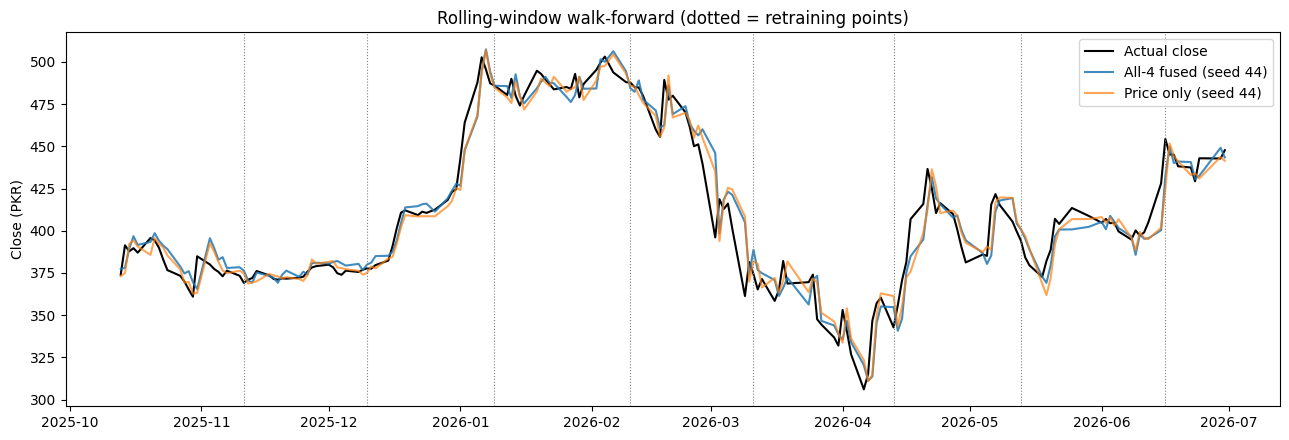

In [81]:
import matplotlib.pyplot as plt
FUSED = "All-4 fused" if "All-4 fused" in WF_MODELS else WF_MODELS[-1]
p = wf[wf.Model == FUSED].set_index("DATE").sort_index()

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(p.index, p.actual, color="black", lw=1.5, label="Actual close")
ax.plot(p.index, p.pred, alpha=.85, label=f"{FUSED} (seed {SEED})")
q = wf[wf.Model == "Price"].set_index("DATE").sort_index()
ax.plot(q.index, q.pred, alpha=.7, label=f"Price only (seed {SEED})")
for d in p.reset_index().groupby("fold").DATE.first().iloc[1:]:
    ax.axvline(d, color="grey", ls=":", lw=.8)
ax.set_title("Rolling-window walk-forward (dotted = retraining points)")
ax.set_ylabel("Close (PKR)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FEAT_DIR}/wf_rolling_predictions.png", dpi=200); plt.show()